# Scout churn model (synthetic data)

A walkthrough of `coursework/churn/`, with steps matching `NOTES.md` [N1]…[N10]. **All Scouts are synthetic.** Run `bash coursework/run_coursework.sh` first; this notebook reads its outputs and calls the same functions.

In [1]:
# Find the repo root (the folder that contains coursework/) and make it importable.
import os, sys
from pathlib import Path
root = Path.cwd()
while not (root / "coursework").is_dir():
    root = root.parent
sys.path.insert(0, str(root)); os.chdir(root)
print("repo root:", root)

repo root: /home/user/manhattan-bars-ml


## Load the tables (live_sim.db if present, else the marked stand-in CSVs)

In [2]:
from coursework.churn.load import load
# SYNTHETIC: replace with the real backend tables
data = load()
print('source:', data['source'])
for k in ['scouts', 'reports', 'ledger', 'bounties', 'rep_history']:
    print(f'{k:12s}', len(data[k]))

source: standin
scouts       150
reports      1739
ledger       1807
bounties     108
rep_history  6711


## [N2]–[N3] Two snapshots: features before the cutoff, label in the 21 days after

In [3]:
from coursework.churn.build_dataset import build, FEATURES, TRAIN_CUTOFF, TEST_CUTOFF
train, test = build(data, TRAIN_CUTOFF), build(data, TEST_CUTOFF)
for name, df in [('train', train), ('test', test)]:
    print(f'{name}: {len(df)} Scouts, base rate {df.churned.mean():.1%}')
train.head()

train: 64 Scouts, base rate 29.7%
test: 86 Scouts, base rate 36.0%


,scout_id,cutoff,tenure_days,cohort_week,reports_28d,reports_7d,days_since_last_report,active_nights_28d,mean_gap_days,trend,...,distinct_venues_28d,share_saturday_reports,points_28d,points_total,bounties_claimed_28d,reputation_asof,points_asof,level_asof,churned,is_synthetic
0,syn-s-0001,2026-10-01,29.791667,0,4,2,5.397917,4,4.666667,1.333333,...,2,0.000000,40,40,0,0.6720,40,1,0,1
1,syn-s-0002,2026-10-01,34.833333,0,1,0,27.493750,1,7.000000,-0.333333,...,1,0.000000,0,10,0,0.4091,10,1,1,1
2,syn-s-0003,2026-10-01,31.125000,0,5,2,4.409722,4,7.666667,1.000000,...,2,0.600000,50,50,0,0.7048,50,1,1,1
3,syn-s-0004,2026-10-01,35.125000,0,11,0,11.531944,7,2.555556,-3.666667,...,6,0.333333,110,180,0,0.9250,180,1,0,1
4,syn-s-0005,2026-10-01,34.750000,0,9,0,11.456250,7,3.000000,-3.000000,...,4,0.500000,80,115,0,0.7666,115,1,0,1


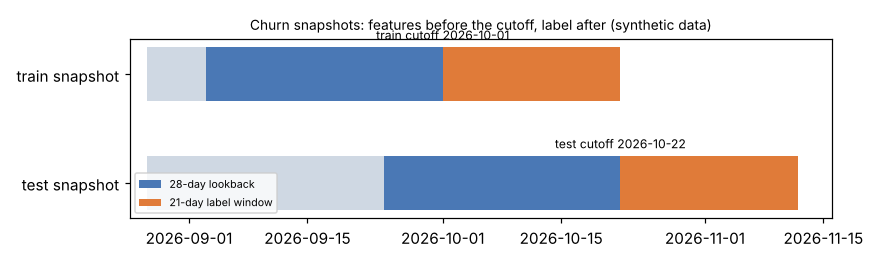

In [4]:
from IPython.display import Image, display
display(Image('coursework/churn/outputs/timeline.png'))

## [N4] Leakage check: delete everything after the cutoff, the features must not change

In [5]:
import pandas as pd
cut = pd.Timestamp(f'{TRAIN_CUTOFF} 12:00', tz='America/New_York')
trimmed = dict(data, reports=data['reports'][data['reports'].ts < cut], ledger=data['ledger'][data['ledger'].ts < cut])
print('features identical:', build(trimmed, TRAIN_CUTOFF)[FEATURES].equals(train[FEATURES]))

features identical: True


## [N5]–[N8] Results: 5 models, CV on train, one out-of-time test (from `outputs/metrics.json`)

In [6]:
import json
m = json.loads(Path('coursework/churn/outputs/metrics.json').read_text())
rows = [{'model': n, 'settings': r['params'], 'cv_auc': round(r['cv_auc_mean'], 3), 'test_auc': round(r['test']['roc_auc'], 3),
         'test_auc_ci': [round(v, 2) for v in r['test_roc_auc_ci']], 'test_pr_auc': round(r['test']['pr_auc'], 3),
         'base_rate': round(r['test']['base_rate'], 3), 'brier': round(r['test']['brier'], 3), 'f1': round(r['test']['f1'], 2)}
        for n, r in m['models'].items()]
print('selected by CV:', m['selected_model'])
pd.DataFrame(rows)

selected by CV: logistic


,model,settings,cv_auc,test_auc,test_auc_ci,test_pr_auc,base_rate,brier,f1
0,majority,{},0.500,0.500,"[0.5, 0.5]",0.360,0.36,0.360,0.53
1,logistic,{'C': 0.1},0.841,0.826,"[0.73, 0.91]",0.760,0.36,0.170,0.69
2,tree,{'max_depth': 3},0.740,0.719,"[0.6, 0.82]",0.496,0.36,0.228,0.70
3,forest,{'min_samples_leaf': 5},0.804,0.787,"[0.68, 0.88]",0.651,0.36,0.180,0.68
4,boosting,{'learning_rate': 0.1},0.738,0.755,"[0.64, 0.86]",0.602,0.36,0.201,0.69


## [N6] Logistic regression odds ratios (per +1 SD), refit live

In [7]:
from coursework.churn.train_eval import make_model
from coursework.churn.explain import odds_ratio_table
lr = make_model('logistic', m['models']['logistic']['params']).fit(train[FEATURES], train.churned)
odds_ratio_table(lr).head(8)

,feature,coef_per_sd,odds_ratio_per_sd
6,mean_gap_days,0.540520,1.716899
10,median_distance_m,-0.336198,0.714482
5,active_nights_28d,-0.290529,0.747868
4,days_since_last_report,0.289850,1.336227
11,distinct_venues_28d,-0.271920,0.761915
8,share_verified_presence,-0.214041,0.807316
3,reports_7d,-0.207868,0.812314
0,tenure_days,0.197315,1.218128


## [N7] The shallow tree as text

In [8]:
from sklearn.tree import export_text
tree = make_model('tree', m['models']['tree']['params']).fit(train[FEATURES], train.churned)
print(export_text(tree[-1], feature_names=FEATURES, decimals=1, show_weights=True))

|--- mean_gap_days <= 4.8
|   |--- distinct_venues_28d <= 1.5
|   |   |--- weights: [1.4, 8.4] class: 1
|   |--- distinct_venues_28d >  1.5
|   |   |--- reports_7d <= 0.5
|   |   |   |--- weights: [4.3, 6.7] class: 1
|   |   |--- reports_7d >  0.5
|   |   |   |--- weights: [24.9, 0.0] class: 0
|--- mean_gap_days >  4.8
|   |--- days_since_last_report <= 6.5
|   |   |--- weights: [0.0, 11.8] class: 1
|   |--- days_since_last_report >  6.5
|   |   |--- weights: [1.4, 5.1] class: 1



## [N8]–[N9] Curves, calibration, importance and the targeting view

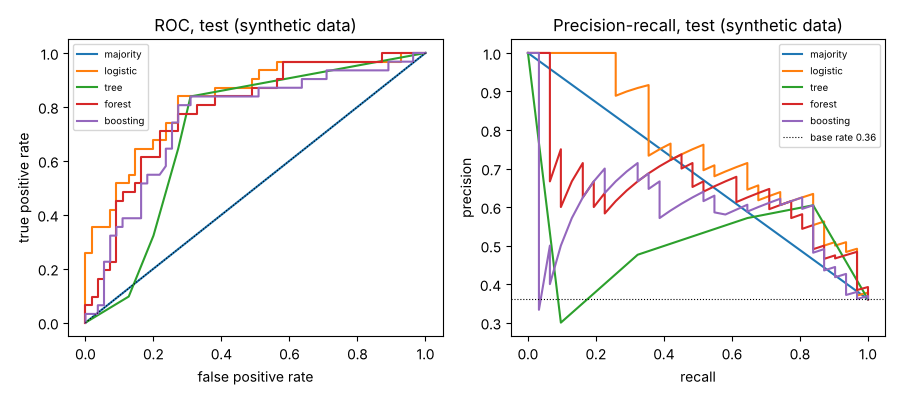

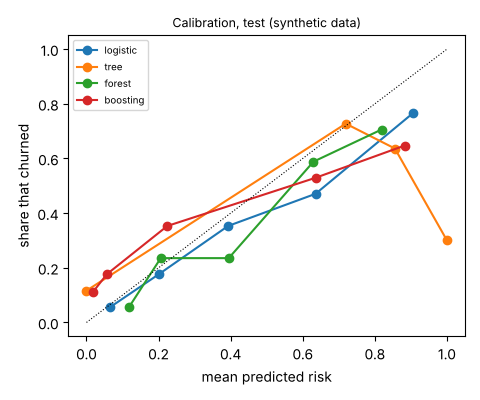

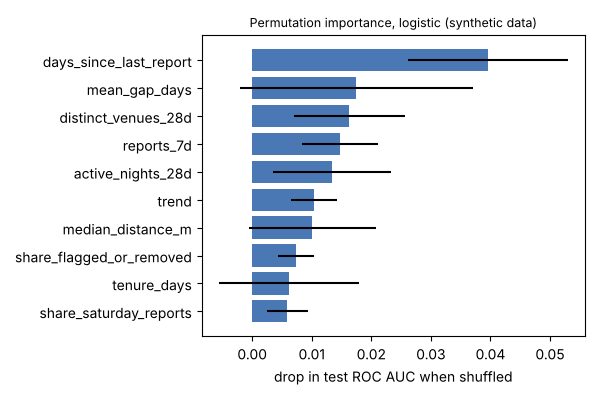

In [9]:
for png in ['roc_pr_test', 'calibration_test', 'permutation_importance']:
    display(Image(f'coursework/churn/outputs/{png}.png'))

In [10]:
from coursework.churn.explain import top_risk_table
top_risk_table(lr, test)

,riskiest share,scouts,churned,churn rate,lift vs base
0,10%,9,8,0.888889,2.465950
1,25%,22,16,0.727273,2.017595
2,50%,43,26,0.604651,1.677419


## Evaluation-only truth check and limitations

See the last section of `outputs/report.md` (written by `evaluate_truth.py`, the only file that reads the simulator's truth table) and `NOTES.md` [N10].